In [2]:
import pandas as pd

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

print(df.columns)


Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


In [4]:
# Frequency table for 'category'
category_counts = df['category'].value_counts(dropna=False).rename_axis('category').reset_index(name='count')
print(category_counts)


                                   category   count
0                         Sports & Outdoors  836265
1                                    Beauty   19312
2    Handmade Clothing, Shoes & Accessories   19229
3                               Bath & Body   19092
4                            Birthday Gifts   18978
..                                      ...     ...
291                       Motorbike Chassis     107
292                  Alexa Built-In Devices     107
293                                   Plugs     107
294          Smart Home Security & Lighting     104
295                          Smart Speakers      54

[296 rows x 2 columns]


In [5]:
top5 = category_counts.head(5)
print("Top 5", top5)

Top 5                                  category   count
0                       Sports & Outdoors  836265
1                                  Beauty   19312
2  Handmade Clothing, Shoes & Accessories   19229
3                             Bath & Body   19092
4                          Birthday Gifts   18978


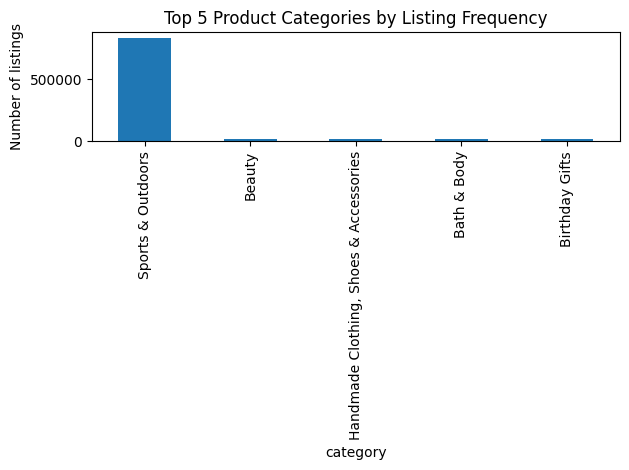

In [6]:
import matplotlib.pyplot as plt
top5.plot.bar(x='category', y='count', legend=False)
plt.ylabel('Number of listings')
plt.title('Top 5 Product Categories by Listing Frequency')
plt.tight_layout()
plt.show()

In [7]:
df.price.isnull().sum()

np.int64(0)

In [8]:
mean_price = df.price.mean()
print(mean_price)

89.24380943923663


In [9]:
median_price = df.price.median()
print(median_price)

19.09


In [10]:
mode_price=df.price.mode()
print(mode_price)

0    9.99
Name: price, dtype: float64


In [11]:
# Big right tail cause mean is much greather than median, meaning some high values of prices are tailing us to right

In [12]:
std_price = df.price.std()
print(std_price)

345.60886175349884


In [13]:
# Very big range of variability in this case mean is not representative

In [14]:
df.price.value_counts().sort_index(ascending=False).head(50)

price
100000.00    1
77752.00     1
24674.59     1
23482.73     1
22933.42     1
21999.00     2
21464.82     3
20489.75     1
20216.00     1
20015.45     1
19999.00     4
19990.00     1
19290.93     1
19211.51     1
18244.80     1
18169.83     1
18144.00     1
17837.54     1
17611.51     1
17139.30     1
16999.00     1
16367.43     1
16113.99     1
16000.00     2
15999.00     1
15991.55     1
15952.79     1
15767.15     1
15736.30     1
15654.93     1
15636.29     1
14852.21     1
14611.22     1
14548.73     1
14416.67     1
14371.79     1
14265.71     1
13999.00     7
13938.62     1
13866.09     1
13803.93     1
13738.37     1
13649.93     1
13457.50     1
13422.17     1
13355.87     1
13316.09     1
13281.07     1
13269.99     1
13174.31     1
Name: count, dtype: int64

In [15]:
price=df.price

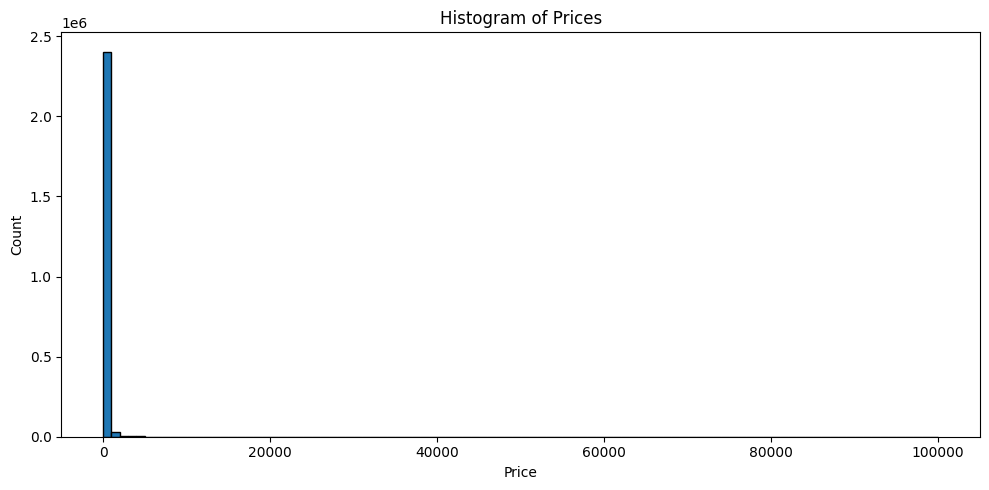

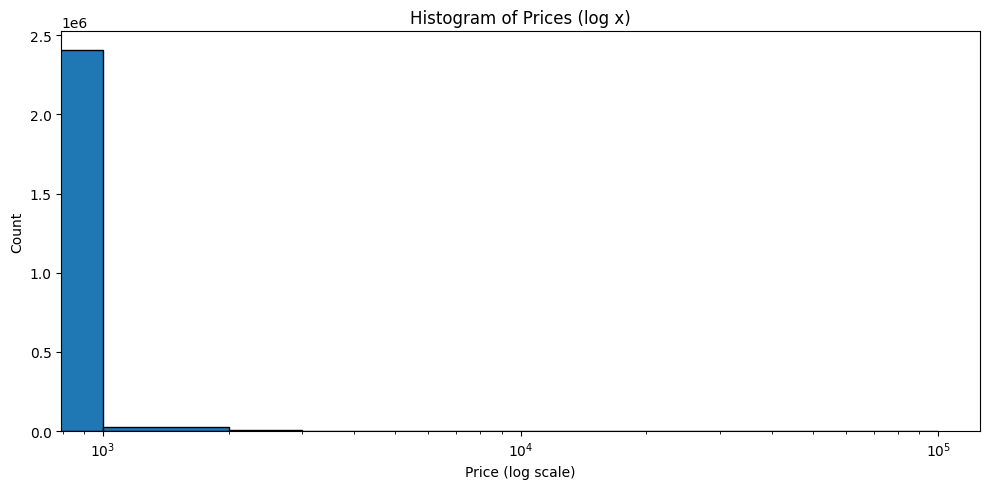

In [16]:
plt.figure(figsize=(10,5))
plt.hist(price, bins=100, color='C0', edgecolor='k')
plt.xlabel('Price')
plt.ylabel('Count')
plt.title('Histogram of Prices')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,5))
plt.hist(price, bins=100, color='C0', edgecolor='k')
plt.xscale('log')
plt.xlabel('Price (log scale)')
plt.ylabel('Count')
plt.title('Histogram of Prices (log x)')
plt.tight_layout()
plt.show()

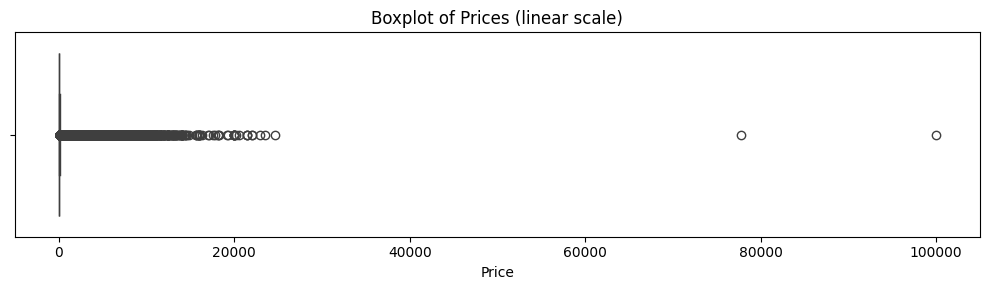

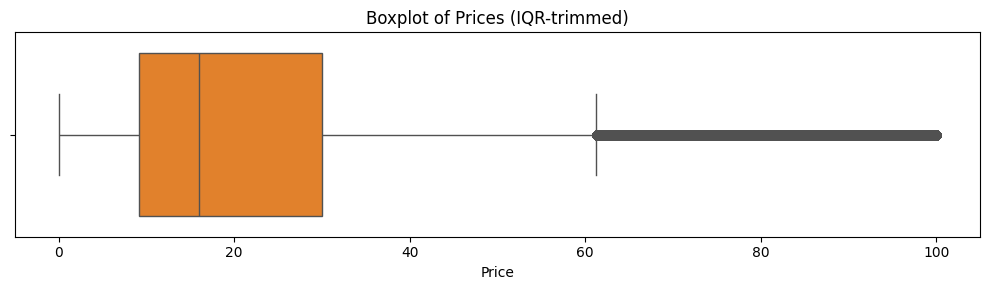

lower bound (1.5×IQR) = -8.01
Q1=9.99, Q3=45.99, IQR=36.00
Upper bound (1.5×IQR) = 99.99
Extreme upper (3×IQR) = 153.99
Outliers >1.5×IQR: 327688 rows
Extreme outliers >3×IQR: 239650 rows
Outliers <1.5×IQR: 2115963 rows


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# general
plt.figure(figsize=(10,3))
sns.boxplot(x=price, orient='h', color='C0')
plt.title('Boxplot of Prices (linear scale)')
plt.xlabel('Price')
plt.tight_layout()
plt.show()

# IQR
q1 = price.quantile(0.25)
q3 = price.quantile(0.75)
iqr = q3 - q1
upper_1_5 = q3 + 1.5 * iqr
upper_3 = q3 + 3 * iqr
lower_1_5 = q3 - 1.5 * iqr

outliers_1_5 = df[df['price'] > upper_1_5].sort_values('price', ascending=False)
outliers_3 = df[df['price'] > upper_3].sort_values('price', ascending=False)
outliers_5_1 = df[df['price'] < upper_1_5].sort_values('price', ascending=False)

prices_pure = price[(price >= lower_1_5) & (price <= upper_1_5)]

plt.figure(figsize=(10,3))
sns.boxplot(x=prices_pure, orient='h', color='C1')
plt.title('Boxplot of Prices (IQR-trimmed)')
plt.xlabel('Price')
plt.tight_layout()
plt.show()


print(f"lower bound (1.5×IQR) = {lower_1_5:.2f}")
print(f"Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}")
print(f"Upper bound (1.5×IQR) = {upper_1_5:.2f}")
print(f"Extreme upper (3×IQR) = {upper_3:.2f}")
print(f"Outliers >1.5×IQR: {len(outliers_1_5)} rows")
print(f"Extreme outliers >3×IQR: {len(outliers_3)} rows")
print(f"Outliers <1.5×IQR: {len(outliers_5_1)} rows")

In [18]:
rat=df.stars
rat.head(50)

0     4.7
1     4.7
2     4.7
3     4.7
4     4.6
5     4.7
6     4.7
7     4.7
8     4.7
9     4.5
10    4.8
11    4.6
12    4.6
13    4.5
14    4.7
15    4.6
16    4.6
17    4.6
18    4.5
19    4.5
20    4.6
21    4.8
22    4.7
23    4.7
24    4.5
25    0.0
26    4.5
27    4.7
28    4.8
29    4.7
30    4.4
31    4.4
32    4.4
33    4.3
34    4.8
35    4.8
36    4.6
37    4.7
38    4.7
39    4.8
40    4.5
41    4.7
42    4.7
43    4.6
44    4.7
45    4.6
46    4.7
47    4.5
48    4.5
49    4.1
Name: stars, dtype: float64

In [19]:
#we should drop goods where rakining is 0.0

In [20]:
dfnn = df[df['stars'] != 0.0].copy()

In [21]:
rate = dfnn.stars
rate.head(20)

0     4.7
1     4.7
2     4.7
3     4.7
4     4.6
5     4.7
6     4.7
7     4.7
8     4.7
9     4.5
10    4.8
11    4.6
12    4.6
13    4.5
14    4.7
15    4.6
16    4.6
17    4.6
18    4.5
19    4.5
Name: stars, dtype: float64

In [22]:
rate.median()

np.float64(4.4)

In [23]:
rate.mode()

0    4.5
Name: stars, dtype: float64

In [24]:
rate.mean()

np.float64(4.31916076222691)

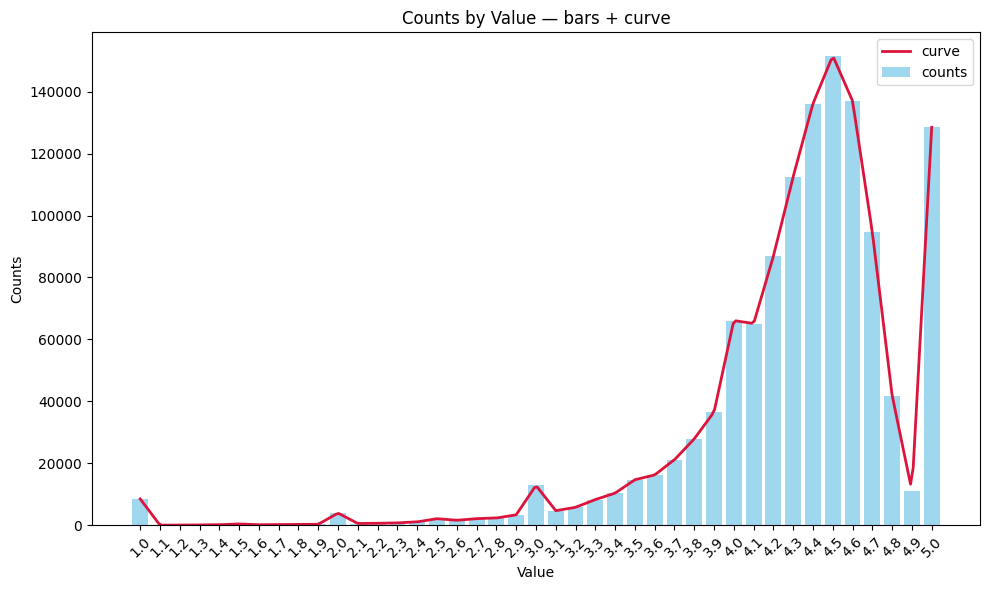

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

counts = rate.value_counts().sort_index()   
values = counts.index.astype(str)           
freq = counts.values                        

x_pos = np.arange(len(values))

plt.figure(figsize=(10,6))


plt.bar(x_pos, freq, color='skyblue', alpha=0.8, label='counts')


x_fine = np.linspace(x_pos.min(), x_pos.max(), 300)
y_fine = np.interp(x_fine, x_pos, freq)
plt.plot(x_fine, y_fine, color='crimson', linewidth=2, label='curve')

plt.xticks(x_pos, values, rotation=45)
plt.xlabel('Value')  
plt.ylabel('Counts')  
plt.title('Counts by Value — bars + curve')
plt.legend()
plt.tight_layout()
plt.show()
